# Watching a digital twin expire

**MG1218 Digital Factories · guest lecture · live demo**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gunnerwang/gunnerwang.github.io/blob/main/teaching/mg1218/MG1218_live_demo.ipynb)
In Colab, choose *File → Save a copy in Drive* to keep your own changes.

This notebook rebuilds the opening case of the lecture: a final-assembly line whose simulation model
was about 2 % off in month 1 and about 19 % off in month 6, while the planners kept using it.
It follows the four parts of the lecture:

1. **Build**: fit a twin from the first week of logs
2. **Fail**: compare the twin with the floor, day by day
3. **Use**: ask the twin a question a planner would ask
4. **Maintain**: an expiry signal, then recalibrate, and regenerate when recalibrating is not enough

It needs Python 3 with `numpy` and `matplotlib` (Anaconda and Google Colab have both), and runs in a few seconds.
Run all cells from the top. Then change a setting in section 1 and run again (ideas in section 9).

*The line and the numbers are illustrative, chosen to match the opening case.*

## 1. Settings
Everything you may want to change is in this cell.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---- the line (the opening case of the lecture) --------------------------
STATIONS   = ["Op 10", "Op 20", "Op 30", "Op 40"]
TIME_LIGHT = [50.0, 55.0, 56.0, 48.0]   # mean processing time [s], light variant
TIME_HEAVY = [52.0, 60.0, 64.0, 50.0]   # mean processing time [s], heavy variant
SPREAD     = [0.08, 0.25, 0.08, 0.10]   # coefficient of variation; Op 20 is a manual station
BUFFERS    = [3, 3, 3]                  # B1, B2, B3: parts that fit between neighbouring stations

# ---- what happens on the floor over six months ---------------------------
WEEKS          = 26
WEAR_SECONDS   = 8.0    # tool wear: Op 30 is this much slower after six months
HEAVY_START    = 0.30   # share of the heavy variant at commissioning ...
HEAVY_END      = 0.38   # ... and after six months
REBALANCE_WEEK = 16     # month 4: Op 20 and Op 30 rebalanced, buffer B2 removed (99 = never)
MOVED_SECONDS  = 2.0    # work moved from Op 30 to Op 20 at the rebalance
MINOR_STOPS    = 0.015  # short stops on the floor, which the twin does not model

# ---- the decision the twin supports --------------------------------------
PLANNED_PER_WEEK = 4100   # parts already planned per week
EXTRA_ORDER      = 300    # "can we take 300 extra parts this week without overtime?"

# ---- the expiry signal ---------------------------------------------------
TOLERANCE = 4.0   # % cycle-time error the decision can live with (CUSUM: k)
THRESHOLD = 8.0   # raise the alarm when the summed excess passes this (CUSUM: h)

SEED = 2          # change it to see another six months of the same line

## 2. The line, and a simulator for it

Four stations in a row, with small buffers between them. Each part is a light or a heavy variant.
A station can only pass a part on when there is room downstream ("blocking after service"),
so a slow or erratic station holds up its neighbours. The same function simulates both the real floor
and the twin; they differ only in the numbers they are given.

```
Op 10 → [B1] → Op 20 (manual) → [B2] → Op 30 → [B3] → Op 40
```

In [2]:
PARTS_PER_DAY, DAYS_PER_WEEK, WARMUP = 900, 5, 60   # two shifts a day, five days a week
HOURS_PER_WEEK = DAYS_PER_WEEK * 15.0
BLUE, SKY, RED, GREEN, GREY, MARINE = "#004791", "#6298D2", "#D8351E", "#3F824E", "#A5A5A5", "#08004F"

def simulate(mean_light, mean_heavy, heavy_share, buffers, spread, n_parts, rng, slowdown=1.0):
    # Returns the mean cycle time of the line [s per part], and a log of what each part did.
    m = len(mean_light)
    heavy = rng.random(n_parts) < heavy_share
    means = np.where(heavy[:, None], np.array(mean_heavy)[None, :], np.array(mean_light)[None, :])
    sigma = np.sqrt(np.log(1 + np.array(spread) ** 2))[None, :]
    p = means * np.exp(rng.normal(-sigma ** 2 / 2, sigma, size=means.shape)) * slowdown
    leave = np.zeros((n_parts, m))            # when part n leaves station j
    for n in range(n_parts):
        for j in range(m):
            arrived = leave[n, j - 1] if j > 0 else 0.0
            free = leave[n - 1, j] if n > 0 else 0.0
            t = max(arrived, free) + p[n, j]
            if j < m - 1 and n - buffers[j] - 1 >= 0:   # wait for room downstream
                t = max(t, leave[n - buffers[j] - 1, j + 1])
            leave[n, j] = t
    cycle_time = (leave[-1, -1] - leave[WARMUP, -1]) / (n_parts - 1 - WARMUP)
    return cycle_time, heavy, p

def months_axis(ax):
    ax.set_xticks([w * 26 / 6 for w in range(7)])
    ax.set_xticklabels([f"M{m}" for m in range(7)])
    ax.set_xlim(0, 26)
    ax.spines[["top", "right"]].set_visible(False)

def save(fig, name):            # used only to export the figures for the slides
    if globals().get("SAVE_FIGS"):
        fig.savefig(f"{FIG_DIR}/{name}.pdf", bbox_inches="tight")

## 3. Six months on the floor

Three things change, and nobody writes any of them back into the twin:
Op 30 slowly gets slower (tool wear), the mix moves towards the heavy variant,
and in month 4 Op 20 and Op 30 are rebalanced and the buffer between them removed, so one operator can serve both.

In [3]:
def floor_in_week(week):
    f = week / (WEEKS - 1)
    light, heavy = list(TIME_LIGHT), list(TIME_HEAVY)
    light[2] += WEAR_SECONDS * f
    heavy[2] += WEAR_SECONDS * f
    buffers = list(BUFFERS)
    if week >= REBALANCE_WEEK:
        for t in (light, heavy):
            t[2] -= MOVED_SECONDS
            t[1] += MOVED_SECONDS
        buffers[1] = 0
    return light, heavy, HEAVY_START + (HEAVY_END - HEAVY_START) * f, buffers

rng = np.random.default_rng(SEED)
floor_ct, logs, week_of_day = [], [], []
for w in range(WEEKS):
    light, heavy, share, buffers = floor_in_week(w)
    for d in range(DAYS_PER_WEEK):
        stops = 1 + rng.gamma(4.0, MINOR_STOPS / 4.0)          # a bad day has more short stops
        ct, hv, p = simulate(light, heavy, share, buffers, SPREAD, PARTS_PER_DAY, rng, slowdown=stops)
        floor_ct.append(ct); week_of_day.append(w)
        logs.append((hv, p / stops))                            # the MES logs processing times only
floor_ct, week_of_day = np.array(floor_ct), np.array(week_of_day)
day_x = week_of_day + (np.arange(len(floor_ct)) % DAYS_PER_WEEK) / DAYS_PER_WEEK

for w in (0, 8, REBALANCE_WEEK, WEEKS - 1):
    if w < WEEKS:
        light, heavy, share, buffers = floor_in_week(w)
        print(f"week {w:2d}:  Op 30 light/heavy = {light[2]:.1f}/{heavy[2]:.1f} s   heavy share = {share:.0%}   buffers = {buffers}")

week  0:  Op 30 light/heavy = 56.0/64.0 s   heavy share = 30%   buffers = [3, 3, 3]
week  8:  Op 30 light/heavy = 58.6/66.6 s   heavy share = 33%   buffers = [3, 3, 3]
week 16:  Op 30 light/heavy = 59.1/67.1 s   heavy share = 35%   buffers = [3, 0, 3]
week 25:  Op 30 light/heavy = 62.0/70.0 s   heavy share = 38%   buffers = [3, 0, 3]


## 4. Build: a twin from the first week of logs

The twin gets what a commissioning team would give it: the layout (stations and buffers)
and, for each station and variant, the processing times measured in week 1.

In [4]:
def fit_twin(days, buffers):
    hv = np.concatenate([logs[i][0] for i in days])
    p = np.concatenate([logs[i][1] for i in days])
    light, heavy = p[~hv].mean(axis=0), p[hv].mean(axis=0)
    spread = (p / np.where(hv[:, None], heavy, light)).std(axis=0)
    return dict(light=list(light), heavy=list(heavy), spread=list(spread),
                share=float(hv.mean()), buffers=list(buffers))

def twin_cycle_time(twin):
    rng = np.random.default_rng(7)
    ct, _, _ = simulate(twin["light"], twin["heavy"], twin["share"], twin["buffers"], twin["spread"], 6000, rng)
    return ct

twin_v1 = fit_twin(days=range(0, DAYS_PER_WEEK), buffers=BUFFERS)
ct_v1 = twin_cycle_time(twin_v1)
for s, l, h in zip(STATIONS, twin_v1["light"], twin_v1["heavy"]):
    print(f"{s}:  light {l:5.1f} s   heavy {h:5.1f} s")
print(f"heavy share {twin_v1['share']:.0%};  the twin's cycle time: {ct_v1:.1f} s per part")

Op 10:  light  50.0 s   heavy  52.0 s
Op 20:  light  55.3 s   heavy  59.6 s
Op 30:  light  56.1 s   heavy  64.0 s
Op 40:  light  48.1 s   heavy  50.1 s
heavy share 30%;  the twin's cycle time: 58.5 s per part


## 5. Fail: compare the twin with the floor, day by day

The error is how much longer the floor's cycle time is than the twin's.
There is no single day on which the twin breaks.

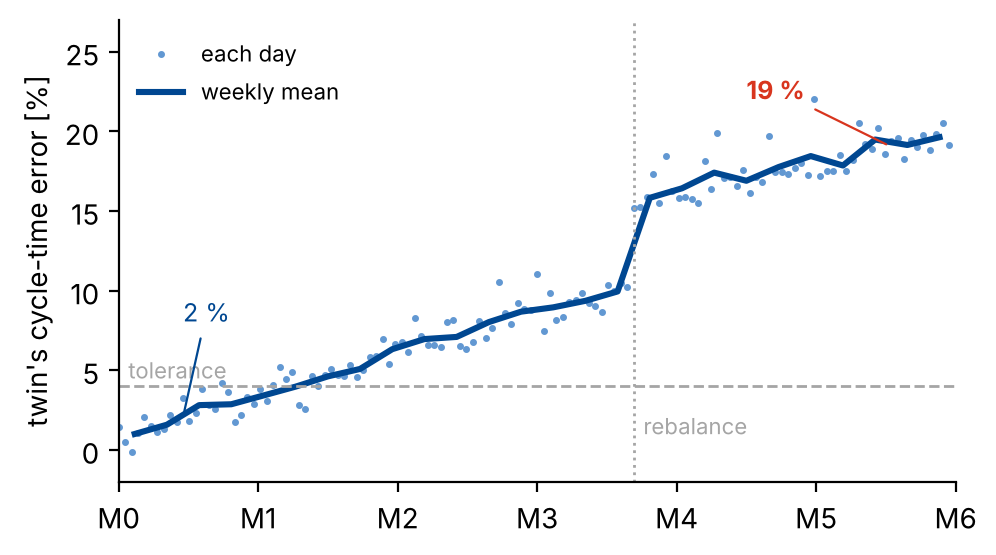

month 1: twin off by  2.3 %
month 2: twin off by  5.0 %
month 3: twin off by  7.7 %
month 4: twin off by 12.1 %
month 5: twin off by 17.6 %
month 6: twin off by 19.0 %


In [5]:
err_v1 = 100 * (floor_ct - ct_v1) / ct_v1
weekly = np.array([err_v1[week_of_day == w].mean() for w in range(WEEKS)])

fig, ax = plt.subplots(figsize=(5.4, 3.0))
ax.plot(day_x, err_v1, ".", color=SKY, ms=3, label="each day")
ax.plot(np.arange(WEEKS) + 0.5, weekly, color=BLUE, lw=2.2, label="weekly mean")
ax.axhline(TOLERANCE, color=GREY, ls="--", lw=1)
ax.text(0.3, TOLERANCE + 0.5, "tolerance", color=GREY, fontsize=8)
if REBALANCE_WEEK < WEEKS:
    ax.axvline(REBALANCE_WEEK, color=GREY, ls=":", lw=1)
    ax.text(REBALANCE_WEEK + 0.3, 1, "rebalance", color=GREY, fontsize=8)
ax.annotate(f"{weekly[:4].mean():.0f} %", (2, weekly[:4].mean()), (2, weekly[:4].mean() + 6),
            color=BLUE, fontsize=9, arrowprops=dict(arrowstyle="-", color=BLUE, lw=0.8))
ax.annotate(f"{weekly[-4:].mean():.0f} %", (24, weekly[-4:].mean()), (19.5, weekly[-4:].mean() + 3),
            color=RED, fontsize=9, fontweight="bold", arrowprops=dict(arrowstyle="-", color=RED, lw=0.8))
months_axis(ax); ax.set_ylabel("twin's cycle-time error [%]"); ax.set_ylim(-2, 27)
ax.legend(frameon=False, fontsize=8, loc="upper left")
save(fig, "demo_error"); plt.show()

for m in range(6):
    sel = (week_of_day >= m * 26 / 6) & (week_of_day < (m + 1) * 26 / 6)
    print(f"month {m + 1}: twin off by {err_v1[sel].mean():4.1f} %")

## 6. Use: a question a planner asks every week

*"Can we take 300 extra parts this week without overtime?"*
The planner reads the spare capacity off the twin. What does the floor actually have?

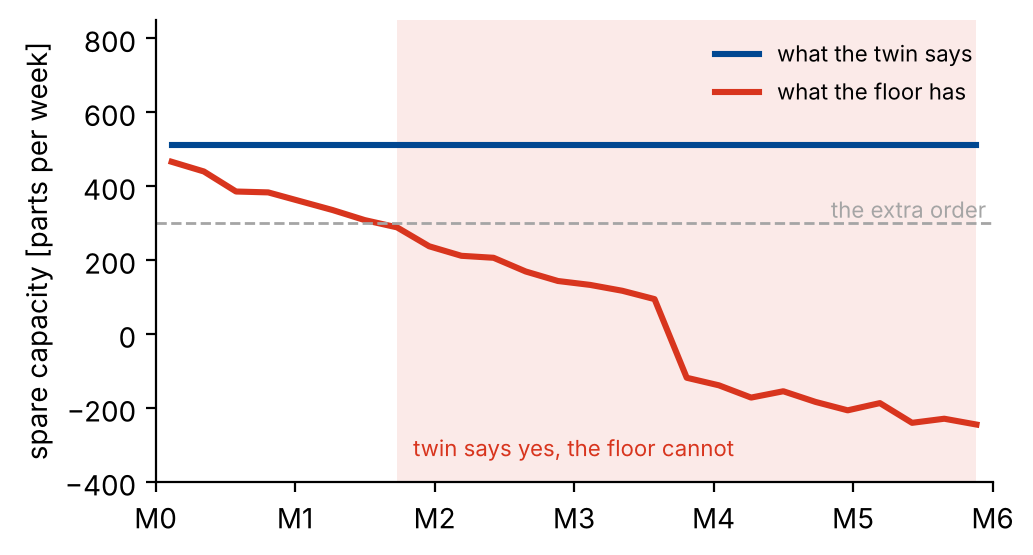

From week 8, the twin's answer is wrong. The twin is then off by 5.1 %, not 19 %.


In [6]:
spare_twin = HOURS_PER_WEEK * 3600 / ct_v1 - PLANNED_PER_WEEK
spare_floor = np.array([HOURS_PER_WEEK * 3600 / floor_ct[week_of_day == w].mean() - PLANNED_PER_WEEK
                        for w in range(WEEKS)])
weeks = np.arange(WEEKS) + 0.5
wrong = (spare_twin >= EXTRA_ORDER) & (spare_floor < EXTRA_ORDER)

fig, ax = plt.subplots(figsize=(5.4, 3.0))
ax.fill_between(weeks, -400, 850, where=wrong, color=RED, alpha=0.10, step="mid", lw=0)
ax.plot(weeks, np.full(WEEKS, spare_twin), color=BLUE, lw=2.2, label="what the twin says")
ax.plot(weeks, spare_floor, color=RED, lw=2.2, label="what the floor has")
ax.axhline(EXTRA_ORDER, color=GREY, ls="--", lw=1)
ax.text(25.8, EXTRA_ORDER + 15, "the extra order", color=GREY, fontsize=8, ha="right")
if wrong.any():
    ax.text(weeks[wrong][0] + 0.5, -330, "twin says yes, the floor cannot", color=RED, fontsize=8)
months_axis(ax); ax.set_ylabel("spare capacity [parts per week]"); ax.set_ylim(-400, 850)
ax.legend(frameon=False, fontsize=8, loc="upper right")
save(fig, "demo_decision"); plt.show()

if wrong.any():
    first = int(np.argmax(wrong))
    print(f"From week {first + 1}, the twin's answer is wrong. The twin is then off by {weekly[first]:.1f} %, not 19 %.")

## 7. Maintain: an expiry signal

A CUSUM detector (Page, 1954): each day, add up how far the error is above the tolerance,
never going below zero. When the sum passes the threshold, raise the alarm.
A low threshold warns early but also raises more false alarms; a high one is quieter but later.

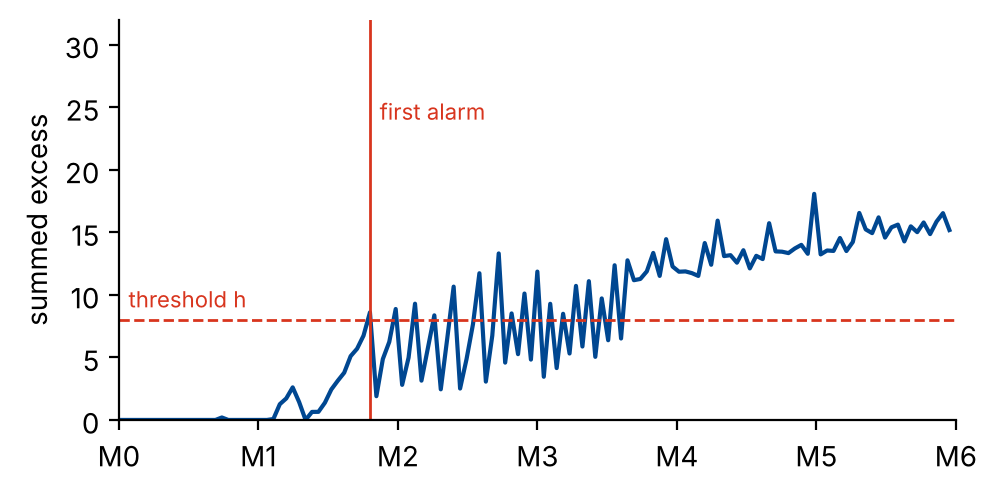

First alarm in week 8, when the twin is off by about 5.1 %.


In [7]:
def cusum(errors, k=TOLERANCE, h=THRESHOLD):
    s, path, alarms = 0.0, [], []
    for i, e in enumerate(errors):
        s = max(0.0, s + e - k)
        path.append(s)
        if s > h:
            alarms.append(i)
            s = 0.0
    return np.array(path), alarms

path, alarms = cusum(err_v1)
fig, ax = plt.subplots(figsize=(5.4, 2.6))
ax.plot(day_x, path, color=BLUE, lw=1.5)
ax.axhline(THRESHOLD, color=RED, ls="--", lw=1)
ax.text(0.3, THRESHOLD + 1, "threshold h", color=RED, fontsize=8)
if alarms:
    ax.axvline(day_x[alarms[0]], color=RED, lw=1)
    ax.text(day_x[alarms[0]] + 0.3, THRESHOLD * 3, "first alarm", color=RED, fontsize=8)
months_axis(ax); ax.set_ylabel("summed excess"); ax.set_ylim(0, max(THRESHOLD * 4, path.max() * 1.05))
plt.show()
if alarms:
    print(f"First alarm in week {week_of_day[alarms[0]] + 1}, when the twin is off by about {weekly[week_of_day[alarms[0]]]:.1f} %.")

## 8. Maintain: recalibrate, and regenerate when that is not enough

When the alarm fires, **recalibrate**: refit the processing times and the mix from the last week of logs,
keeping the twin's layout. Then watch one more week. If the error is still clearly above the tolerance,
the parameters were not the problem: walk the floor, update the layout, and **regenerate** the twin.

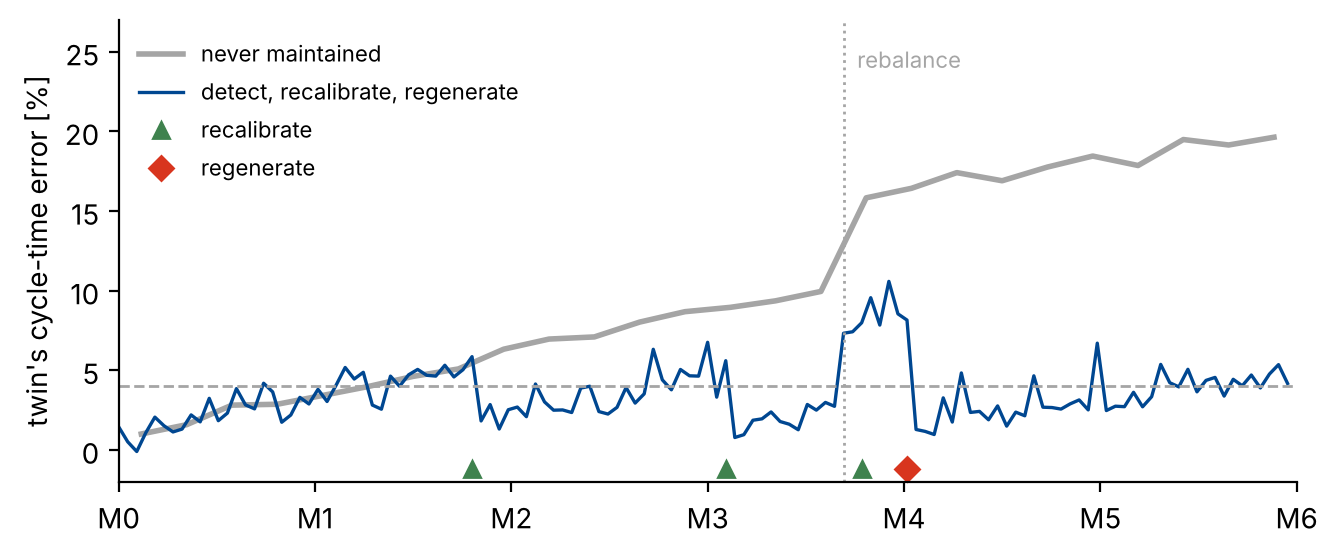

week  8: recalibrate
week 14: recalibrate
week 17: recalibrate
week 18: regenerate


In [8]:
def last_week(i):
    return range(i - DAYS_PER_WEEK + 1, i + 1)

twin, ct_twin = twin_v1, ct_v1
s, checking, err_kept, events = 0.0, None, [], []
for i, ct in enumerate(floor_ct):
    e = 100 * (ct - ct_twin) / ct_twin
    err_kept.append(e)
    if checking is not None:                       # the week after a recalibration
        checking.append(e)
        if len(checking) == DAYS_PER_WEEK:
            if np.mean(checking) > TOLERANCE + 1.0:
                layout = floor_in_week(week_of_day[i])[3]
                twin = fit_twin(last_week(i), buffers=layout)
                ct_twin = twin_cycle_time(twin)
                events.append((i, "regenerate"))
            checking = None
        continue
    s = max(0.0, s + e - TOLERANCE)
    if s > THRESHOLD:
        twin = fit_twin(last_week(i), buffers=twin["buffers"])
        ct_twin = twin_cycle_time(twin)
        events.append((i, "recalibrate"))
        s, checking = 0.0, []
err_kept = np.array(err_kept)

fig, ax = plt.subplots(figsize=(7.6, 3.0))
ax.plot(np.arange(WEEKS) + 0.5, weekly, color=GREY, lw=2, label="never maintained")
ax.plot(day_x, err_kept, color=BLUE, lw=1.2, label="detect, recalibrate, regenerate")
ax.axhline(TOLERANCE, color=GREY, ls="--", lw=1)
for i, what in events:
    c, mk = (GREEN, "^") if what == "recalibrate" else (RED, "D")
    ax.plot(day_x[i], -1.2, mk, color=c, ms=6, clip_on=False)
ax.plot([], [], "^", color=GREEN, label="recalibrate"); ax.plot([], [], "D", color=RED, label="regenerate")
if REBALANCE_WEEK < WEEKS:
    ax.axvline(REBALANCE_WEEK, color=GREY, ls=":", lw=1)
    ax.text(REBALANCE_WEEK + 0.3, 24, "rebalance", color=GREY, fontsize=8)
months_axis(ax); ax.set_ylabel("twin's cycle-time error [%]"); ax.set_ylim(-2, 27)
ax.legend(frameon=False, fontsize=8, loc="upper left")
save(fig, "demo_maintain"); plt.show()

for i, what in events:
    print(f"week {week_of_day[i] + 1:2d}: {what}")

## 9. Try it yourself

Change one setting in section 1, run all cells again, and explain what you see.

* `THRESHOLD = 3` or `THRESHOLD = 20`: how often do you recalibrate, and how large does the error get in between?
* `REBALANCE_WEEK = 99`: no structural change. Is regenerating ever needed?
* `WEAR_SECONDS = 0`: only the mix drifts. How long does the twin last now?
* `TOLERANCE = 2`: a stricter decision. What does that cost in recalibrations?
* `EXTRA_ORDER = 150`: a smaller order. From which week is the twin's answer wrong now?

Questions to think about: what is the *maintenance interval* of this twin? Who should own the alarm?
And which of these settings would you have to measure on a real line before you could trust them?